<a href="https://colab.research.google.com/github/tishasetia13/planet-or-not/blob/main/planet_or_not_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install lightkurve

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.1/261.1 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 81.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 83.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.2/336.2 kB 21.9 MB/s eta 0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11427 sha256=1bbf31f096e330dc9374cf9523ef2d080c4436fb5ca429adaf55e1cca4028bda
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/2

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 4 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 01 2009 Kepler    1800 kplr006922244      0.0
  1 Kepler Quarter 02 2009 Kepler    1800 kplr006922244      0.0
  2 Kepler Quarter 03 2009 Kepler    1800 kplr006922244      0.0
  3 Kepler Quarter 04 2010 Kepler    1800 kplr006922244      0.0


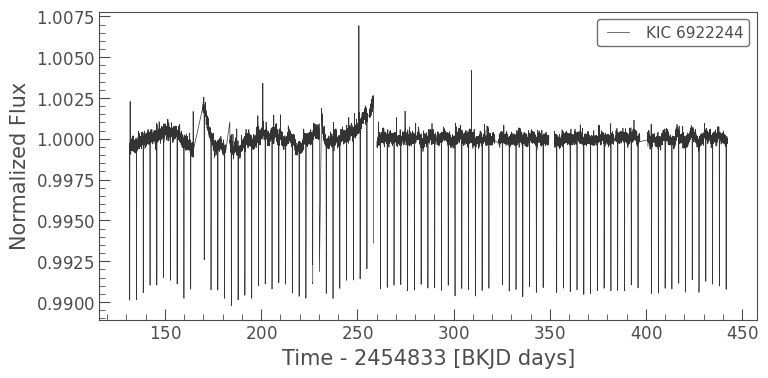

In [2]:
import lightkurve as lk
import matplotlib.pyplot as plt

search_result = lk.search_lightcurve("Kepler-8", author="Kepler", cadence="long", quarter=[1, 2, 3, 4])
print(search_result)

lc_collection = search_result.download_all()

lc = lc_collection.stitch()

lc.plot()
plt.show()

In [4]:
import pandas as pd

CSV_PATH = 'koi_cumulative.csv'

def load_koi_table(path):
  return pd.read_csv(path, comment='#')

koi = load_koi_table(CSV_PATH)

print("Rows and columns:", koi.shape)
print(koi["koi_disposition"].value_counts())

print(list(koi.columns))

Rows and columns: (9564, 141)
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64
['rowid', 'kepid', 'kepoi_name', 'kepler_name', 'koi_disposition', 'koi_vet_stat', 'koi_vet_date', 'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_disp_prov', 'koi_comment', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_time0', 'koi_time0_err1', 'koi_time0_err2', 'koi_eccen', 'koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_ror', 'koi_ror_err1', 'koi_ror_err2', 'koi_srho', 'koi_srho_err1', 'koi_srho_err2', 'koi_fittype', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_sma'

In [5]:
def missing_report(df):
  counts = df.isna().sum()
  percent = (counts / len(df) * 100).round(1)
  report = pd.DataFrame({'missing': counts, 'percent': percent})
  return report.sort_values("missing", ascending=False)

print(missing_report(koi).head(25))

wanted = ["kepid", "kepoi_name", "koi_disposition", "koi_period",
          "koi_time0bk", "koi_depth", "koi_prad", "koi_model_snr"]

def check_columns(df, names):
  for name in names:
    print(f"{name:18} found: {name in df.columns}")

check_columns(koi, wanted)

                  missing  percent
koi_incl_err1        9564    100.0
koi_sma_err2         9564    100.0
koi_sma_err1         9564    100.0
koi_teq_err1         9564    100.0
koi_teq_err2         9564    100.0
koi_longp_err2       9564    100.0
koi_ingress          9564    100.0
koi_ingress_err2     9564    100.0
koi_ingress_err1     9564    100.0
koi_longp_err1       9564    100.0
koi_longp            9564    100.0
koi_eccen_err2       9564    100.0
koi_eccen_err1       9564    100.0
koi_sage_err1        9564    100.0
koi_sage_err2        9564    100.0
koi_sage             9564    100.0
koi_model_dof        9564    100.0
koi_model_chisq      9564    100.0
koi_incl_err2        9564    100.0
kepler_name          6816     71.3
koi_bin_oedp_sig     1510     15.8
koi_score            1510     15.8
koi_comment          1209     12.6
koi_max_sngle_ev     1142     11.9
koi_quarters         1142     11.9
kepid              found: True
kepoi_name         found: True
koi_disposition    found: Tr

In [6]:
# test cell
def list_columns(df):
    """Print one line per column: position, name, data type, number of empty cells."""
    for position, name in enumerate(df.columns):
        empty = df[name].isna().sum()                 # count of empty cells in this column
        print(f"{position:3d}  {name:28s} {str(df[name].dtype):9s} empty={empty}")

list_columns(koi)

  0  rowid                        int64     empty=0
  1  kepid                        int64     empty=0
  2  kepoi_name                   object    empty=0
  3  kepler_name                  object    empty=6816
  4  koi_disposition              object    empty=0
  5  koi_vet_stat                 object    empty=0
  6  koi_vet_date                 object    empty=0
  7  koi_pdisposition             object    empty=0
  8  koi_score                    float64   empty=1510
  9  koi_fpflag_nt                int64     empty=0
 10  koi_fpflag_ss                int64     empty=0
 11  koi_fpflag_co                int64     empty=0
 12  koi_fpflag_ec                int64     empty=0
 13  koi_disp_prov                object    empty=0
 14  koi_comment                  object    empty=1209
 15  koi_period                   float64   empty=0
 16  koi_period_err1              float64   empty=454
 17  koi_period_err2              float64   empty=454
 18  koi_time0bk                  float64   empty=0

In [7]:
def labeled_only(df):
    """Return a copy of the table containing only CONFIRMED and FALSE POSITIVE rows."""
    keep = df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])
    return df[keep].copy()

labeled = labeled_only(koi)
print("Labeled rows:", len(labeled))

def leak_report(df):
    """Print three tables showing how the suspect columns line up with the label."""
    label = df["koi_disposition"]

    print("1) Is kepler_name filled?")
    print(pd.crosstab(label, df["kepler_name"].notna()), "\n")

    print("2) koi_pdisposition (the Kepler pipeline's own verdict)")
    print(pd.crosstab(label, df["koi_pdisposition"]), "\n")

    print("3) Average koi_score and share of rows flagged, per label")
    suspects = ["koi_score", "koi_fpflag_nt", "koi_fpflag_ss",
                "koi_fpflag_co", "koi_fpflag_ec"]
    print(df.groupby("koi_disposition")[suspects].mean().round(3))

leak_report(labeled)

Labeled rows: 7587
1) Is kepler_name filled?
kepler_name      False  True 
koi_disposition              
CONFIRMED            2   2746
FALSE POSITIVE    4837      2 

2) koi_pdisposition (the Kepler pipeline's own verdict)
koi_pdisposition  CANDIDATE  FALSE POSITIVE
koi_disposition                            
CONFIRMED              2739               9
FALSE POSITIVE            1            4838 

3) Average koi_score and share of rows flagged, per label
                 koi_score  koi_fpflag_nt  koi_fpflag_ss  koi_fpflag_co  \
koi_disposition                                                           
CONFIRMED            0.960          0.170          0.005           0.00   
FALSE POSITIVE       0.038          0.315          0.457           0.39   

                 koi_fpflag_ec  
koi_disposition                 
CONFIRMED                0.000  
FALSE POSITIVE           0.237  


In [8]:
# important cell that is doing some modifications to the data that we are going to feed to the model. what we are doing here is - dropping and selecting the columns and inputs that goes into the model.
answer_key_cols = [
    "kepler_name", "koi_pdisposition", "koi_score",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
    "koi_comment", "koi_vet_stat", "koi_vet_date",
    "koi_datalink_dvr", "koi_datalink_dvs",
]

empty_cols = [c for c in koi.columns if koi[c].isna().all()]
print("Empty columns:", len(empty_cols))        # expect 19

koi_small = koi.drop(columns=answer_key_cols + empty_cols)
print("Before:", koi.shape, " After:", koi_small.shape)    # expect 141 -> 110 columns

Empty columns: 19
Before: (9564, 141)  After: (9564, 110)


In [9]:
# same function as the upper one, but for different columns

err_cols = [c for c in koi_small.columns if c.endswith(("_err", "_err1", "_err2"))]
print("Uncertainty columns:", len(err_cols))

koi_small = koi_small.drop(columns=err_cols)
print("Now:", koi_small.shape)

Uncertainty columns: 44
Now: (9564, 66)


In [10]:
# same function as the upper one, but for different columns

paperwork_cols = [
    "koi_disp_prov", "koi_parm_prov", "koi_tce_delivname", "koi_tce_plnt_num",
    "koi_fittype", "koi_limbdark_mod", "koi_trans_mod", "koi_sparprov",
    "koi_quarters", "koi_bin_oedp_sig", "koi_count",
]

koi_small = koi_small.drop(columns=paperwork_cols)
print("Now:", koi_small.shape)

Now: (9564, 55)


In [11]:
pixel_cols = [c for c in koi_small.columns
              if c.startswith(("koi_fwm_", "koi_dicco_", "koi_dikco_"))]
print("Picture columns:", len(pixel_cols))

koi_small = koi_small.drop(columns=pixel_cols)
print("Now:", koi_small.shape)

Picture columns: 13
Now: (9564, 42)


In [12]:
# test cell

# Stage 1: name the columns that have special jobs (they are not model inputs)
id_cols   = ["rowid", "kepid", "kepoi_name"]    # say which object each row is
label_col = "koi_disposition"                   # the answer we want to predict
fold_cols = ["koi_time0bk", "koi_time0"]        # needed later to fold light curves

# Stage 2: everything else is a candidate model input
special = id_cols + [label_col] + fold_cols
feature_cols = [c for c in koi_small.columns if c not in special]

print("Special columns:", len(special))         # expect 6
print("Input columns:", len(feature_cols))      # expect 36
print(feature_cols)

# Stage 3: safety check that no answer-key column is still in the table
leaked = set(answer_key_cols) & set(koi_small.columns)
print("Answer-key columns still present:", leaked)   # expect set()

Special columns: 6
Input columns: 36
['koi_period', 'koi_eccen', 'koi_impact', 'koi_duration', 'koi_depth', 'koi_ror', 'koi_srho', 'koi_prad', 'koi_sma', 'koi_incl', 'koi_teq', 'koi_insol', 'koi_dor', 'koi_ldm_coeff4', 'koi_ldm_coeff3', 'koi_ldm_coeff2', 'koi_ldm_coeff1', 'koi_max_sngle_ev', 'koi_max_mult_ev', 'koi_model_snr', 'koi_num_transits', 'koi_steff', 'koi_slogg', 'koi_smet', 'koi_srad', 'koi_smass', 'ra', 'dec', 'koi_kepmag', 'koi_gmag', 'koi_rmag', 'koi_imag', 'koi_zmag', 'koi_jmag', 'koi_hmag', 'koi_kmag']
Answer-key columns still present: set()


In [13]:
# cell where we select the rows that goes into the model, just like we did for the columns

# Stage 1: mark each row True if its label is CONFIRMED or FALSE POSITIVE
keep_rows = koi_small[label_col].isin(["CONFIRMED", "FALSE POSITIVE"])

# Stage 2: keep only the marked rows, as a separate copy called clean
clean = koi_small[keep_rows].copy()
print("Clean table:", clean.shape)                  # expect (7587, 42)

# Stage 3: count each label and the share that are real planets
print(clean[label_col].value_counts())              # expect FALSE POSITIVE 4839, CONFIRMED 2748
print("Share confirmed:", round((clean[label_col] == "CONFIRMED").mean(), 3))   # expect 0.362

Clean table: (7587, 42)
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
Name: count, dtype: int64
Share confirmed: 0.362
